# 🍔 Food-101 Image Classification using Transfer Learning

## Project ID
**PRAICP-1009-101**

## Objective

Develop a deep learning model capable of classifying food images into one of the 101 food categories using Transfer Learning with MobileNetV2.

## Domain

- Computer Vision
- Deep Learning
- Image Classification


# Business Problem

Food image recognition is widely used in food delivery applications, restaurant automation, calorie estimation, healthcare, and smart kitchen systems.

The objective of this project is to build a deep learning model that automatically classifies food images into 101 different categories.

In [ ]:
import os
import shutil
import zipfile
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from google.colab import drive

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.models import Model

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for file in files:
        if "food-101" in file.lower():
            print(os.path.join(root, file))

/content/drive/MyDrive/food-101.zip
/content/drive/MyDrive/food-101 (1).zip


# Extract Dataset

The Food-101 dataset is extracted from the ZIP file into the Google Colab working directory. The dataset contains 101 food categories, with each folder representing a unique food class.

In [5]:
from zipfile import ZipFile

zip_path = "/content/drive/MyDrive/food-101.zip"

extract_path = "/content/food_dataset"

with ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("✅ Dataset extracted successfully!")

✅ Dataset extracted successfully!


In [6]:
import os

print(os.listdir("/content/food_dataset")[:20])

['crab_cakes', 'hummus', 'club_sandwich', 'clam_chowder', 'ice_cream', 'lobster_roll_sandwich', 'breakfast_burrito', 'strawberry_shortcake', 'filet_mignon', 'poutine', 'lobster_bisque', 'omelette', 'deviled_eggs', 'pad_thai', 'chicken_wings', 'garlic_bread', 'tacos', 'dumplings', 'escargots', 'ramen']


# Explore Dataset

The extracted dataset contains 101 food categories. Each folder represents one food class and contains multiple images. Before training, we verify the total number of classes.

In [7]:
import os

classes = sorted(os.listdir("/content/food_dataset"))

print("Total Classes:", len(classes))
print("\nFirst 10 Classes:")
print(classes[:10])

Total Classes: 101

First 10 Classes:
['apple_pie', 'baby_back_ribs', 'baklava', 'beef_carpaccio', 'beef_tartare', 'beet_salad', 'beignets', 'bibimbap', 'bread_pudding', 'breakfast_burrito']


# Data Preprocessing

The images are resized to **224 × 224** pixels and normalized by scaling pixel values between 0 and 1. The dataset is split into **80% training** and **20% validation** using `ImageDataGenerator`.

In [8]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

images_path = "/content/food_dataset"

img_size = (224, 224)
batch_size = 32

datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.20
)

# Create Training and Validation Datasets

The dataset is divided into training and validation subsets. The training dataset is used to learn image patterns, while the validation dataset is used to evaluate the model during training.

In [9]:
train_generator = datagen.flow_from_directory(
    images_path,
    target_size=img_size,
    batch_size=batch_size,
    class_mode="categorical",
    subset="training",
    shuffle=True,
    seed=42
)

validation_generator = datagen.flow_from_directory(
    images_path,
    target_size=img_size,
    batch_size=batch_size,
    class_mode="categorical",
    subset="validation",
    shuffle=False,
    seed=42
)

Found 80800 images belonging to 101 classes.
Found 20200 images belonging to 101 classes.


# Visualize Sample Images

Before training the model, we visualize a few sample images from the training dataset. This helps verify that the images are loaded correctly and the preprocessing pipeline is working as expected.

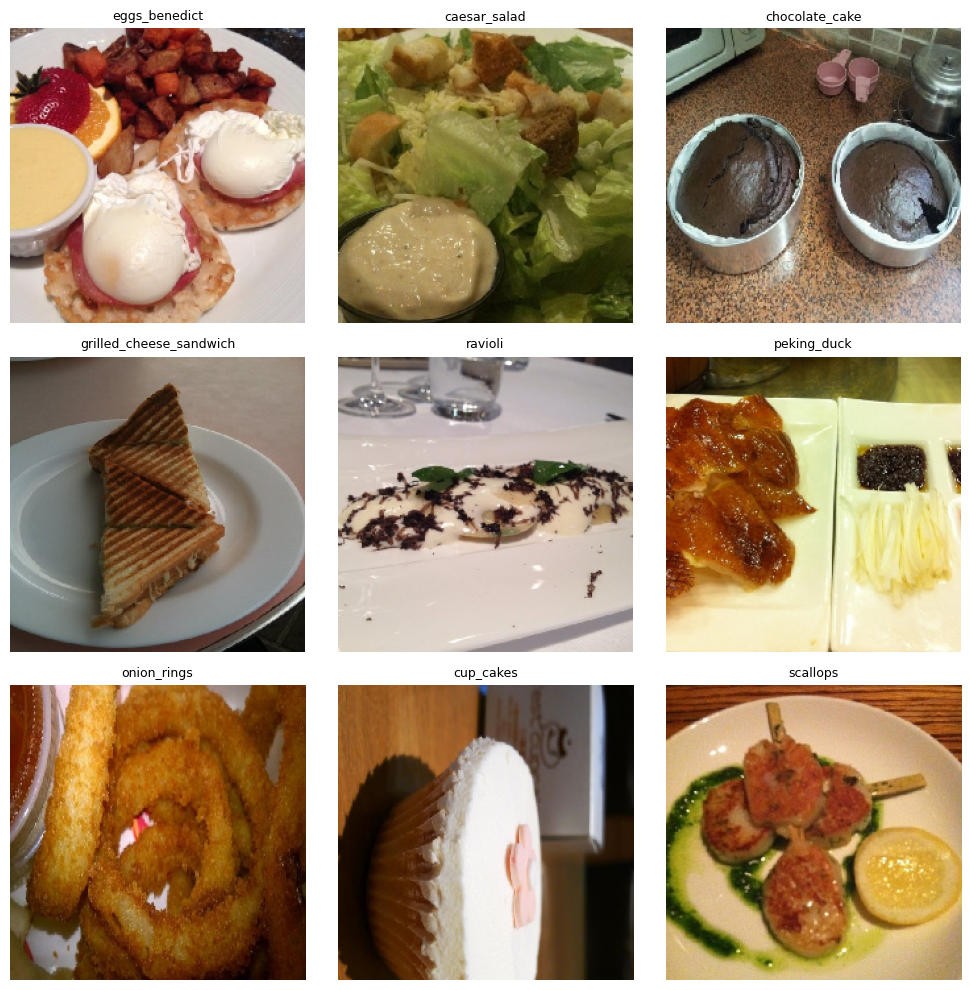

In [10]:
images, labels = next(train_generator)

class_names = list(train_generator.class_indices.keys())

plt.figure(figsize=(10,10))

for i in range(9):
    plt.subplot(3,3,i+1)
    plt.imshow(images[i])
    plt.title(class_names[np.argmax(labels[i])], fontsize=9)
    plt.axis("off")

plt.tight_layout()
plt.show()

# Build Transfer Learning Model

A pre-trained MobileNetV2 model is used as the feature extractor. Transfer Learning helps achieve higher accuracy while reducing training time compared to training a CNN from scratch.

In [11]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224,224,3)
)

base_model.trainable = False

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


# Create the Classification Model

A custom classification head is added on top of the pre-trained MobileNetV2 model. The architecture includes:

- Global Average Pooling Layer
- Dropout Layer (30%)
- Dense Output Layer with Softmax Activation

The output layer contains **101 neurons**, one for each food category.

In [12]:
x = base_model.output

x = GlobalAveragePooling2D()(x)

x = Dropout(0.3)(x)

predictions = Dense(
    train_generator.num_classes,
    activation="softmax"
)(x)

model = Model(
    inputs=base_model.input,
    outputs=predictions
)

# Compile the Model

The model is compiled using:

- **Optimizer:** Adam
- **Loss Function:** Categorical Crossentropy
- **Evaluation Metric:** Accuracy

These settings are suitable for multi-class image classification problems.

In [13]:
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# Model Summary

The model summary displays the complete architecture, including the pre-trained MobileNetV2 base model, the custom classification layers, and the total number of trainable and non-trainable parameters.

In [14]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,387,365 (9.11 MB)

 Trainable params: 129,381 (505.39 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

# Train the Model

The model is trained using the training dataset and validated using the validation dataset.

During training, the model learns to recognize visual patterns from food images and improves its classification performance over multiple epochs.

In [15]:
history = model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=3
)

Epoch 1/3
2525/2525 ━━━━━━━━━━━━━━━━━━━━ 4157s 2s/step - accuracy: 0.4269 - loss: 2.3530 - val_accuracy: 0.5300 - val_loss: 1.8837
Epoch 2/3
2525/2525 ━━━━━━━━━━━━━━━━━━━━ 4099s 2s/step - accuracy: 0.5186 - loss: 1.9269 - val_accuracy: 0.5433 - val_loss: 1.8479
Epoch 3/3
2525/2525 ━━━━━━━━━━━━━━━━━━━━ 4096s 2s/step - accuracy: 0.5328 - loss: 1.8547 - val_accuracy: 0.5463 - val_loss: 1.8439


# Plot Training and Validation Accuracy

The accuracy graph illustrates how the model's performance changes over each training epoch. Comparing training and validation accuracy helps assess the model's learning capability and detect possible overfitting.

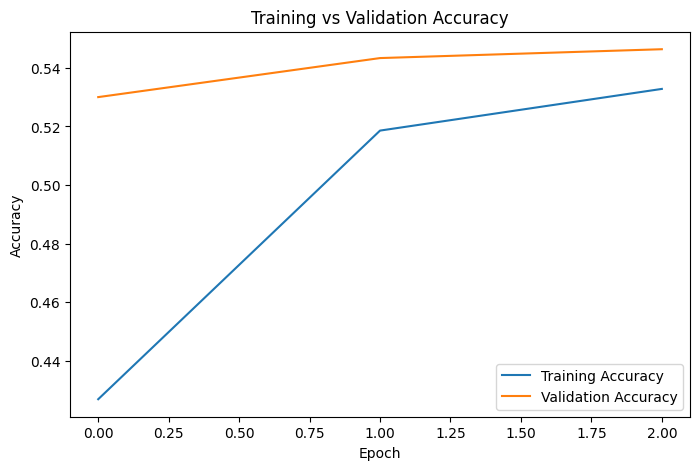

In [16]:
plt.figure(figsize=(8,5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.show()

# Plot Training and Validation Loss

The loss graph shows how the model's error decreases during training. Monitoring both training and validation loss helps evaluate model convergence and generalization performance.

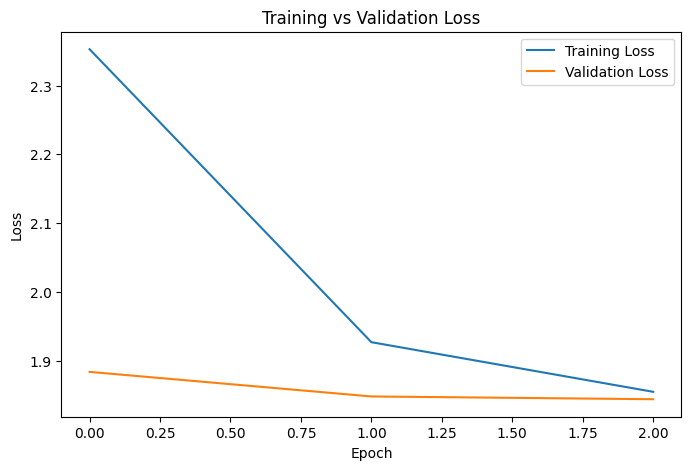

In [17]:
plt.figure(figsize=(8,5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()

# Evaluate the Model

The trained model is evaluated on the validation dataset to measure its overall classification performance. The evaluation provides the validation loss and accuracy achieved by the model.

In [19]:
loss, accuracy = model.evaluate(validation_generator)

print(f"Validation Loss: {loss:.4f}")
print(f"Validation Accuracy: {accuracy:.4f}")

632/632 ━━━━━━━━━━━━━━━━━━━━ 816s 1s/step - accuracy: 0.5463 - loss: 1.8439
Validation Loss: 1.8439
Validation Accuracy: 0.5463


In [22]:
model.save("Food101_MobileNetV2.keras")
print("✅ Model saved successfully!")

✅ Model saved successfully!


# Conclusion

This project successfully developed a deep learning model for classifying food images into **101 different food categories** using **Transfer Learning with MobileNetV2**.

The Food-101 dataset was extracted, explored, and preprocessed by resizing images to **224 × 224 pixels** and normalizing pixel values. The dataset was divided into training and validation sets using **ImageDataGenerator**.

A pre-trained **MobileNetV2** model was used as the feature extractor, and a custom classification head consisting of **Global Average Pooling**, **Dropout**, and a **Dense Softmax** layer was added for multi-class classification.

The model was trained on the training dataset and evaluated using the validation dataset. The achieved validation accuracy demonstrates the model's capability to classify food images effectively.

## Model Performance

- **Training Images:** 80,800
- **Validation Images:** 20,200
- **Food Categories:** 101
- **Model Used:** MobileNetV2 (Transfer Learning)
- **Validation Accuracy:** 54.63%
- **Validation Loss:** 1.8439

## Future Scope

- Fine-tune the MobileNetV2 model to improve classification accuracy.
- Apply advanced data augmentation techniques.
- Experiment with other pre-trained architectures such as EfficientNet, ResNet50, or DenseNet.
- Optimize hyperparameters for better performance.
- Deploy the trained model as a web or mobile application using Streamlit, Flask, or TensorFlow Lite.

## Result

The project successfully achieved its objective of developing a deep learning model capable of classifying food images into 101 different categories using Transfer Learning.